[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NavaSergio/SP1-material-estudiantes/blob/main/docs/U4-BD/material/02_ejemplo_calidad_aire.ipynb)

# Ejemplo de punta a punta 1: calidad del aire (tabla plana, series de tiempo)

**Seminario de Proyecto I (MCDI) — Unidad 4: Diseño de bases de datos y recolección de información**

Este notebook recorre, con datos reales, todo el camino de la presentación: de una **pregunta de investigación** a un **dataset listo para análisis** con su **diccionario de datos**, su **README** y la **documentación de cada transformación**. Es el tipo de documentación que se considera **buena práctica**.

| Paso | Qué hacemos | Diapositivas relacionadas |
|---|---|---|
| 1 | Pregunta, objetivos, hipótesis, variables y unidad de análisis | De la pregunta a la base para análisis |
| 2 | Evaluación del origen de los datos (6 dimensiones) | Evaluación del origen de los datos |
| 3 | Carga de los datos crudos y diagnóstico de calidad | Control de calidad de los datos |
| 4 | Limpieza y transformación | De datos crudos a datos listos para análisis |
| 5 | Datos faltantes: patrón, decisiones e imputación | Imputación |
| 6 | Variables derivadas y validaciones | Diccionario de datos |
| 7 | Agregación temporal (hora → día) | Agregación |
| 8 | Entregables: diccionario, README, datasets y estructura de archivos | Organización de archivos |
| 9 | Una primera mirada de uso y lista de verificación | Lista de buenas prácticas |

**Cómo usarlo.** Puedes ejecutarlo en Google Colab (no requiere instalar nada) o en tu computadora (`pip install -r requirements.txt`). Al ejecutarlo se crea la carpeta `proyecto_calidad_aire/` con la estructura recomendada en la presentación.

> **Importante:** este es un *ejemplo*, no una plantilla para copiar. Tu proyecto tendrá otra pregunta, otras variables y otras decisiones; lo que debes replicar es el **razonamiento y la documentación**.

In [1]:
from datetime import date
from pathlib import Path
import io
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

pd.options.display.float_format = "{:.2f}".format
pd.options.display.max_columns = 30
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Estructura de carpetas recomendada en la presentación
RAIZ = Path("proyecto_calidad_aire")
for sub in ["datos/originales", "datos/procesados", "documentos"]:
    (RAIZ / sub).mkdir(parents=True, exist_ok=True)
print("Carpetas listas en:", RAIZ)

Carpetas listas en: proyecto_calidad_aire


## 1. Pregunta, objetivos, hipótesis, variables y unidad de análisis

**Pregunta general.** ¿Qué tan bien se puede estimar la concentración de monóxido de carbono (CO) medida por un analizador de referencia a partir de sensores económicos de óxido metálico y de variables meteorológicas?

**Objetivo general.** Evaluar en qué medida la concentración de CO medida por un analizador de referencia puede estimarse con sensores económicos de óxido metálico y variables meteorológicas.

**Hipótesis general.** La señal de los sensores, junto con la temperatura y la humedad, permite estimar la concentración de CO de referencia en periodos posteriores al de ajuste del modelo.

**Matriz de coherencia.** Cada pregunta específica se conecta con un objetivo, una hipótesis y la variable que permite contrastarla:

| Pregunta específica | Objetivo específico | Hipótesis específica | Variable o métrica en la base | Rol |
|---|---|---|---|---|
| ¿Cuánto se parecen la señal del sensor y la concentración de referencia? | **OE1.** Cuantificar la relación entre la señal del sensor y la concentración de referencia | **H1.** A mayor señal del sensor, mayor concentración de CO de referencia (asociación positiva y fuerte) | `sensor_co` frente a `co_ref` (correlación) | Independiente / dependiente |
| ¿Mejora la estimación al considerar temperatura y humedad? | **OE2.** Determinar si incorporar temperatura y humedad mejora la estimación | **H2.** Al incorporar temperatura y humedad, el error de estimación es menor que usando solo el sensor | `temperatura`, `humedad_rel`, `humedad_abs` | Independientes (control) |
| ¿Cómo varía el CO a lo largo del día y de la semana? | **OE3.** Describir la variación horaria y semanal del CO | **H3.** El CO es mayor en las horas de mayor tráfico y en días laborales que en la madrugada y en fines de semana | `hora_del_dia`, `dia_semana` | Derivadas |
| ¿Cómo se comporta el CO a escala diaria? | **OE4.** Describir la serie diaria de CO y su relación con la estación del año | **H4.** Los promedios diarios de CO son más altos en los meses fríos que en los cálidos | Promedio diario de `co_ref` y número de horas válidas | Agregadas |

Las hipótesis se formulan **antes** de ver los resultados. En este notebook solo comprobamos que la base **permite contrastarlas**.

**Unidad de análisis (qué es una fila).**

- Base **horaria**: una fila = una hora de medición en el sitio de monitoreo (nivel original de los datos).
- Base **diaria**: una fila = un día; se obtiene agregando la base horaria (paso 7).

La unidad de análisis debe corresponder con la pregunta: para estimar CO a partir de sensores conviene la **base horaria**; para estudiar patrones diarios, la **diaria**.

> Regla de la presentación: *si no puedes ubicar una variable en este flujo, todavía no está lista para entrar a tu base.*

## 2. Evaluación del origen de los datos

Antes de usar un dataset respondemos las 6 preguntas de control. Aquí las respuestas se basan en la documentación de la fuente (página del dataset en el UCI Machine Learning Repository y el artículo que lo describe); más adelante las contrastaremos con lo que realmente encontramos en los datos.

| Dimensión | Respuesta documentada | Evidencia / fuente |
|---|---|---|
| **Procedencia** | Datos generados por S. De Vito y colaboradores (ENEA, Italia); publicados en UCI. Son datos de **terceros**, de acceso libre. | Página del dataset en UCI; artículo De Vito et al. (2008) |
| **Generación / recolección** | Un dispositivo multisensor con 5 sensores de óxido metálico, instalado a nivel de calle en una zona muy contaminada de una ciudad italiana. Las concentraciones de referencia (CO, hidrocarburos no metánicos, benceno, NOx, NO₂) provienen de un **analizador certificado** colocado en el mismo sitio. | Documentación UCI |
| **Estructura y alcance** | Promedios **horarios**; una sola estación; periodo anunciado: marzo de 2004 a febrero de 2005. | Documentación UCI (verificaremos el periodo real) |
| **Calidad y confiabilidad** | Se reconocen **sensibilidad cruzada** entre gases y **deriva** de los sensores a lo largo del tiempo; los faltantes se marcan con `-200`. | Documentación UCI y artículo |
| **Transformaciones previas** | Son promedios horarios (ya agregados); no se documenta qué limpieza previa se aplicó. | Documentación UCI |
| **Restricciones y uso** | Licencia CC BY 4.0 según UCI; la página añade que los datos son **solo para uso en investigación, no comercial**. Hay que **citar** el dataset y el artículo. | Página del dataset en UCI |

**Límites de este análisis (los registramos desde ahora):** una sola estación y una sola ciudad, por lo que **no se puede generalizar** a otras zonas; los sensores tienen deriva, así que las relaciones pueden cambiar con el tiempo; la zona horaria y la unidad de la humedad absoluta no están documentadas.

## 3. Carga de los datos crudos y diagnóstico

Descargamos el archivo original **una sola vez** y lo guardamos en `datos/originales/`, donde **no se modifica nunca**. Todo lo demás se hace en memoria o en `datos/procesados/`, mediante código (esto hace el proceso reproducible).

In [2]:
URL = "https://archive.ics.uci.edu/static/public/360/air+quality.zip"
ruta_csv = RAIZ / "datos/originales/AirQualityUCI.csv"
ruta_origen = RAIZ / "datos/originales/origen.txt"

if not ruta_csv.exists():
    peticion = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(peticion, timeout=60) as respuesta:
        contenido = respuesta.read()
    with zipfile.ZipFile(io.BytesIO(contenido)) as z:
        z.extract("AirQualityUCI.csv", RAIZ / "datos/originales")
    ruta_origen.write_text(f"Fuente: {URL}\nFecha de descarga: {date.today().isoformat()}\n", encoding="utf-8")
    print("Archivo descargado.")
else:
    print("Se usa el archivo original ya descargado.")

print(ruta_origen.read_text(encoding="utf-8"))

Archivo descargado.
Fuente: https://archive.ics.uci.edu/static/public/360/air+quality.zip
Fecha de descarga: 2026-10-13



El archivo trae sorpresas típicas de datos reales: separador `;`, **coma decimal** (`2,6`), fechas `dd/mm/aaaa`, horas con puntos (`18.00.00`) y columnas vacías. Lo leemos indicando esas convenciones:

In [3]:
crudo = pd.read_csv(ruta_csv, sep=";", decimal=",", encoding="latin-1")
print("Forma del archivo crudo (filas, columnas):", crudo.shape)
crudo.head()

Forma del archivo crudo (filas, columnas): (9471, 17)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.60,1360.00,150.00,11.90,1046.00,166.00,1056.00,113.00,1692.00,1268.00,13.60,48.90,0.76,NaN,NaN
1,10/03/2004,19.00.00,2.00,1292.00,112.00,9.40,955.00,103.00,1174.00,92.00,1559.00,972.00,13.30,47.70,0.73,NaN,NaN
2,10/03/2004,20.00.00,2.20,1402.00,88.00,9.00,939.00,131.00,1140.00,114.00,1555.00,1074.00,11.90,54.00,0.75,NaN,NaN
3,10/03/2004,21.00.00,2.20,1376.00,80.00,9.20,948.00,172.00,1092.00,122.00,1584.00,1203.00,11.00,60.00,0.79,NaN,NaN
4,10/03/2004,22.00.00,1.60,1272.00,51.00,6.50,836.00,131.00,1205.00,116.00,1490.00,1110.00,11.20,59.60,0.79,NaN,NaN


In [4]:
# Diagnóstico inicial: ¿qué hay realmente en el archivo?
filas_vacias = crudo.isna().all(axis=1)
columnas_vacias = [c for c in crudo.columns if crudo[c].isna().all()]

print(f"Filas completamente vacías:   {filas_vacias.sum()}")
print(f"Columnas completamente vacías: {columnas_vacias}")

df = crudo.loc[~filas_vacias].drop(columns=columnas_vacias).copy()
print(f"\nDespués de quitar filas y columnas vacías: {df.shape}")

Filas completamente vacías:   114
Columnas completamente vacías: ['Unnamed: 15', 'Unnamed: 16']

Después de quitar filas y columnas vacías: (9357, 15)


In [5]:
# La fecha y la hora vienen en columnas separadas, con formatos poco convencionales
df["fecha_hora"] = pd.to_datetime(
    df["Date"] + " " + df["Time"].str.replace(".", ":", regex=False),
    format="%d/%m/%Y %H:%M:%S",
)

malla_completa = pd.date_range(df["fecha_hora"].min(), df["fecha_hora"].max(), freq="h")

print("Primera medición:", df["fecha_hora"].min())
print("Última medición: ", df["fecha_hora"].max())
print("Filas:", len(df), "| horas esperadas en el periodo:", len(malla_completa))
print("Marcas de tiempo duplicadas:", df["fecha_hora"].duplicated().sum())
print("Orden cronológico:", df["fecha_hora"].is_monotonic_increasing)

Primera medición: 2004-03-10 18:00:00
Última medición:  2005-04-04 14:00:00
Filas: 9357 | horas esperadas en el periodo: 9357
Marcas de tiempo duplicadas: 0
Orden cronológico: True


**Hallazgo 1 — contraste con la documentación.** La fuente anuncia el periodo *marzo de 2004 a febrero de 2005*, pero los datos llegan hasta **abril de 2005**. Además, no hay horas faltantes ni duplicadas: la serie horaria está completa. Esto se anota en el README: la documentación y los datos no coinciden exactamente, y por eso conviene **verificar** en lugar de confiar.

Ahora revisamos los valores centinela. Según la fuente, los faltantes se codifican como **`-200`**; si no lo supiéramos, las estadísticas estarían completamente distorsionadas:

In [6]:
numericas = df.select_dtypes("number").columns.tolist()

print("Mínimos antes de tratar el centinela -200:")
print(df[numericas].min().to_string())

print("\nConteo de valores -200 por variable:")
conteo_centinela = (df[numericas] == -200).sum()
print(conteo_centinela.to_string())

Mínimos antes de tratar el centinela -200:
CO(GT)          -200.00
PT08.S1(CO)     -200.00
NMHC(GT)        -200.00
C6H6(GT)        -200.00
PT08.S2(NMHC)   -200.00
NOx(GT)         -200.00
PT08.S3(NOx)    -200.00
NO2(GT)         -200.00
PT08.S4(NO2)    -200.00
PT08.S5(O3)     -200.00
T               -200.00
RH              -200.00
AH              -200.00

Conteo de valores -200 por variable:
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366


## 4. Limpieza y transformación

Decisiones de este paso (todas quedarán documentadas en el diccionario):

1. Convertir `-200` en un faltante real (`NaN`).
2. Dar nombres claros y consistentes a las columnas (sin espacios ni símbolos; `snake_case`).
3. Dejar la fecha-hora como un único campo de tipo fecha.
4. Mantener las unidades que reporta la fuente.

In [7]:
nombres = {
    "CO(GT)": "co_ref",            # CO, analizador de referencia (mg/m3)
    "PT08.S1(CO)": "sensor_co",    # respuesta del sensor orientado a CO
    "NMHC(GT)": "nmhc_ref",        # hidrocarburos no metánicos, referencia (ug/m3)
    "C6H6(GT)": "benceno_ref",     # benceno, referencia (ug/m3)
    "PT08.S2(NMHC)": "sensor_nmhc",
    "NOx(GT)": "nox_ref",          # NOx, referencia (ppb)
    "PT08.S3(NOx)": "sensor_nox",
    "NO2(GT)": "no2_ref",          # NO2, referencia (ug/m3)
    "PT08.S4(NO2)": "sensor_no2",
    "PT08.S5(O3)": "sensor_o3",
    "T": "temperatura",            # grados Celsius
    "RH": "humedad_rel",           # humedad relativa (%)
    "AH": "humedad_abs",           # humedad absoluta (unidad no documentada)
}

horario = (
    df.rename(columns=nombres)
      .drop(columns=["Date", "Time"])
      .replace(-200, np.nan)
)
horario = horario[["fecha_hora"] + list(nombres.values())].reset_index(drop=True)

assert not (horario.drop(columns="fecha_hora") == -200).any().any()
print("Valores -200 restantes: 0")
horario.describe().T[["count", "min", "max"]]

Valores -200 restantes: 0


,count,min,max
fecha_hora,9357,2004-03-10 18:00:00,2005-04-04 14:00:00
co_ref,7674.00,0.10,11.90
sensor_co,8991.00,647.00,2040.00
nmhc_ref,914.00,7.00,1189.00
benceno_ref,8991.00,0.10,63.70
sensor_nmhc,8991.00,383.00,2214.00
nox_ref,7718.00,2.00,1479.00
sensor_nox,8991.00,322.00,2683.00
no2_ref,7715.00,2.00,340.00
sensor_no2,8991.00,551.00,2775.00


## 5. Datos faltantes: patrón, decisiones e imputación

La presentación insiste en que **primero se identifica el mecanismo de ausencia** y luego se elige el método. Veamos cuánto falta y *cómo* falta.

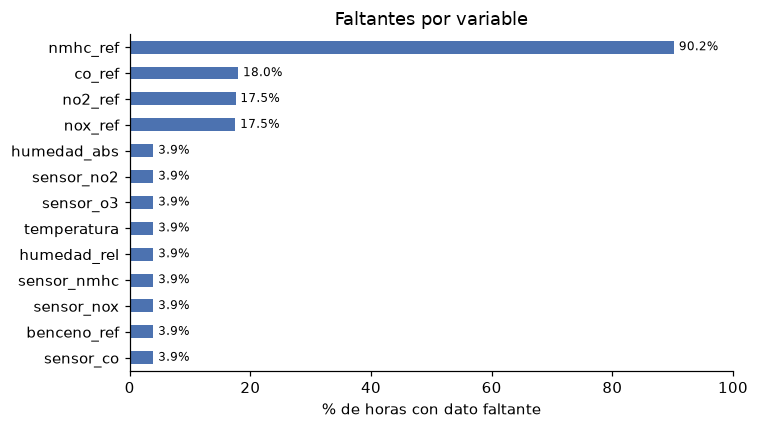

In [8]:
variables = list(nombres.values())
pct_faltante = horario[variables].isna().mean().mul(100).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
pct_faltante.plot.barh(ax=ax, color="#4c72b0")
ax.set_xlabel("% de horas con dato faltante")
ax.set_title("Faltantes por variable")
for i, v in enumerate(pct_faltante):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

In [9]:
# ¿Los faltantes ocurren al mismo tiempo en varias variables? (patrón de ausencia)
sensores = ["sensor_co", "sensor_nmhc", "sensor_nox", "sensor_no2", "sensor_o3"]
meteo = ["temperatura", "humedad_rel", "humedad_abs"]
referencia = ["co_ref", "nmhc_ref", "benceno_ref", "nox_ref", "no2_ref"]

sin_sensores = horario[sensores + meteo + ["benceno_ref"]].isna().all(axis=1)
print(f"Horas en que fallan TODOS los sensores, la meteorología y el benceno: {sin_sensores.sum()} "
      f"({sin_sensores.mean():.1%} de las horas)")

# Bloques consecutivos de falla
bloque = (sin_sensores != sin_sensores.shift()).cumsum()
tamano = sin_sensores.groupby(bloque).agg(["first", "size"])
apagones = tamano[tamano["first"]]["size"].sort_values(ascending=False)
print(f"Número de bloques de falla: {len(apagones)}")
print(f"Duración de los bloques (horas): {apagones.tolist()}")

# El objetivo (co_ref) falta mucho más que los sensores, y casi siempre cuando los sensores SÍ funcionan
co_sin_ref = horario["co_ref"].isna()
print(f"\nHoras sin co_ref: {co_sin_ref.sum()}  | de ellas, con sensores funcionando: {(co_sin_ref & ~sin_sensores).sum()}")

# Los analizadores de referencia, ¿fallan también juntos?
refs_juntas = horario[["co_ref", "nox_ref", "no2_ref"]].isna().all(axis=1)
print(f"Horas en que co_ref, nox_ref y no2_ref faltan a la vez: {refs_juntas.sum()}")

# nmhc_ref: ¿cuándo deja de registrarse?
ultima_nmhc = horario.loc[horario["nmhc_ref"].notna(), "fecha_hora"].max()
print(f"Última hora con nmhc_ref observado: {ultima_nmhc}  | horas observadas en total: {horario['nmhc_ref'].notna().sum()}")

Horas en que fallan TODOS los sensores, la meteorología y el benceno: 366 (3.9% de las horas)
Número de bloques de falla: 16
Duración de los bloques (horas): [76, 75, 52, 45, 38, 24, 14, 10, 9, 8, 5, 4, 3, 1, 1, 1]

Horas sin co_ref: 1683  | de ellas, con sensores funcionando: 1647
Horas en que co_ref, nox_ref y no2_ref faltan a la vez: 1226
Última hora con nmhc_ref observado: 2004-05-01 00:00:00  | horas observadas en total: 914


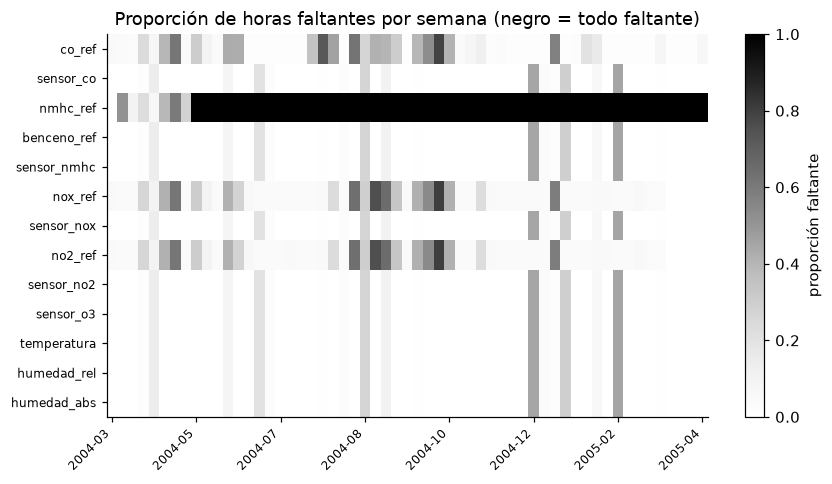

In [10]:
# Mapa de ausencia: cada columna es una variable y cada fila una semana del periodo
mapa = horario.set_index("fecha_hora")[variables].isna().astype(int)
semanal = mapa.resample("W").mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(semanal.T, aspect="auto", cmap="Greys", vmin=0, vmax=1)
ax.set_yticks(range(len(variables)))
ax.set_yticklabels(variables, fontsize=8)
etiquetas = np.arange(0, len(semanal), 8)
ax.set_xticks(etiquetas)
ax.set_xticklabels([semanal.index[i].strftime("%Y-%m") for i in etiquetas], rotation=45, ha="right", fontsize=8)
ax.set_title("Proporción de horas faltantes por semana (negro = todo faltante)")
plt.colorbar(im, ax=ax, label="proporción faltante")
plt.tight_layout()
plt.show()

**Hallazgos sobre el mecanismo de ausencia**

- Los sensores, la meteorología y el benceno **fallan todos a la vez**, en pocos bloques consecutivos que pueden durar días. Es una falla del equipo, **no azar independiente** (no es MCAR): si faltara al azar veríamos huecos dispersos de una hora.
- `co_ref` (nuestra variable a explicar) falta en aproximadamente 18% de las horas, y **casi siempre mientras los sensores sí funcionan**. Cerca de tres cuartas partes de esas horas coinciden con horas en que `nox_ref` y `no2_ref` también faltan: parece que **los analizadores de referencia fallan juntos, en bloques**, independientemente de los sensores. La causa real (mantenimiento o calibración) **no está documentada**, y los datos por sí solos no permiten distinguir entre MAR y MNAR.
- `nmhc_ref` **deja de registrarse después del 1 de mayo de 2004** (el mapa de ausencia lo muestra como una franja negra continua): no es un faltante aleatorio, sino la **interrupción de una medición**. Por eso falta en ~90% de las horas.

**Decisiones por variable** (cada una se justifica y se registra en el diccionario):

| Variable | Faltante | Decisión | Justificación |
|---|---|---|---|
| `nmhc_ref` | ~90% | **Descartar la variable** | La medición se interrumpió en mayo de 2004; imputar casi todos sus valores sería inventar la variable. No se necesita para la pregunta. |
| `co_ref` (variable a explicar) | ~18% | **No imputar; excluir esas horas del análisis** | Imputar la variable dependiente fabricaría la respuesta que queremos estimar. |
| Sensores y meteorología, huecos **cortos** (≤ 3 horas) | pocas horas | **Interpolación temporal** | La temperatura y las señales cambian lentamente; hay vecinos cercanos confiables. |
| Sensores y meteorología, huecos **largos** (> 3 horas) | la mayor parte | **No imputar** (se dejan como faltantes) | Rellenar un apagón de días con una recta no es defendible. |
| Otras referencias (`nox_ref`, `no2_ref`, `benceno_ref`) | 4% – 18% | **No imputar** | No intervienen en la pregunta; se conservan tal cual, con sus faltantes. |

Antes de interpolar, **probamos si el método es razonable**: ocultamos al azar el 10% de las temperaturas que sí conocemos y comparamos qué tan bien las recuperan dos métodos.

In [11]:
# Experimento: ¿qué método recupera mejor valores que sabemos cuánto valen?
rng = np.random.default_rng(42)
serie = horario.set_index("fecha_hora")["temperatura"]

observados = serie.dropna().index
ocultos = rng.choice(observados, size=int(0.10 * len(observados)), replace=False)

con_huecos = serie.copy()
con_huecos.loc[ocultos] = np.nan
verdad = serie.loc[ocultos]

metodos = {
    "Media global": con_huecos.fillna(con_huecos.mean()),
    "Interpolación temporal (≤ 3 h)": con_huecos.interpolate(method="time", limit=3, limit_area="inside"),
}

filas = []
for nombre, estimada in metodos.items():
    est = estimada.loc[ocultos]
    valido = est.notna()
    filas.append({
        "Método": nombre,
        "Horas recuperadas (%)": 100 * valido.mean(),
        "Error medio absoluto (°C)": (est[valido] - verdad[valido]).abs().mean(),
        "Desv. est. de la serie imputada (°C)": estimada.std(),
    })

print(f"Desv. est. de la serie original completa: {serie.std():.2f} °C")
pd.DataFrame(filas).set_index("Método")

Desv. est. de la serie original completa: 8.83 °C


,Horas recuperadas (%),Error medio absoluto (°C),Desv. est. de la serie imputada (°C)
Método,,,
Media global,100.00,7.12,8.23
Interpolación temporal (≤ 3 h),99.78,0.51,8.83


Para huecos cortos, la interpolación temporal recupera los valores con un error mucho menor que la media global, que además **encoge la varianza** de la serie (la desviación estándar baja), justo el defecto que mencionaba la tabla de métodos de imputación de la presentación.

> **Ojo con el alcance del experimento:** ocultamos horas sueltas al azar, que es el caso más favorable para la interpolación. El experimento respalda rellenar huecos **cortos**; no justifica rellenar apagones de días (para eso no hay vecinos cercanos).

Aplicamos entonces las decisiones: descartar `nmhc_ref`, interpolar solo huecos de hasta 3 horas en sensores y meteorología, y **marcar** qué filas tienen valores imputados (transparencia).

In [12]:
horario = horario.drop(columns="nmhc_ref")

a_imputar = sensores + meteo
antes = horario[a_imputar].copy()

serie_tiempo = horario.set_index("fecha_hora")[a_imputar]
imputado = serie_tiempo.interpolate(method="time", limit=3, limit_area="inside")

horario[a_imputar] = imputado.to_numpy()
horario["hay_imputacion"] = (antes.isna() & horario[a_imputar].notna()).any(axis=1)

print("Valores imputados por variable:")
print((antes.isna() & horario[a_imputar].notna()).sum().to_string())
print(f"\nHoras con al menos un valor imputado: {horario['hay_imputacion'].sum()}")
print(f"Horas de sensores/meteorología que siguen faltando (huecos largos): {horario[a_imputar].isna().all(axis=1).sum()}")

Valores imputados por variable:
sensor_co      42
sensor_nmhc    42
sensor_nox     42
sensor_no2     42
sensor_o3      42
temperatura    42
humedad_rel    42
humedad_abs    42

Horas con al menos un valor imputado: 42
Horas de sensores/meteorología que siguen faltando (huecos largos): 324


## 6. Variables derivadas y validaciones

Creamos tres variables derivadas de `fecha_hora` (se registran en el diccionario como *Derivada*), y verificamos con `assert` que la base cumple las reglas que definimos. Si alguna validación falla, el código se detiene: es la **prevención y detección de errores** de la presentación hecha código.

In [13]:
horario["hora_del_dia"] = horario["fecha_hora"].dt.hour
horario["dia_semana"] = horario["fecha_hora"].dt.dayofweek          # 0 = lunes ... 6 = domingo
horario["es_fin_de_semana"] = horario["dia_semana"] >= 5

# ---- Validaciones ----
assert horario["fecha_hora"].is_unique, "Hay marcas de tiempo duplicadas"
assert horario["fecha_hora"].is_monotonic_increasing, "La serie no está ordenada"
assert horario["hora_del_dia"].between(0, 23).all()
assert horario["humedad_rel"].dropna().between(0, 100).all(), "Humedad relativa fuera de rango"
assert horario["temperatura"].dropna().between(-20, 50).all(), "Temperatura fuera de un rango razonable"
for col in ["co_ref", "benceno_ref", "nox_ref", "no2_ref"] + sensores:
    assert (horario[col].dropna() > 0).all(), f"{col} tiene valores no positivos"
print("Todas las validaciones pasaron.")
print("Forma de la base horaria:", horario.shape)

Todas las validaciones pasaron.
Forma de la base horaria: (9357, 17)


## 7. Agregación temporal: de hora a día

Para estudiar patrones diarios agregamos la base horaria. Dos decisiones que quedan documentadas:

- **Función de agregación:** promedio diario.
- **Regla de calidad:** un promedio diario solo se calcula si ese día hay **al menos 18 horas válidas** de la variable (la regla es una decisión del analista; otra regla sería igualmente defendible, pero hay que declararla).

Recuerda: agregar es **irreversible**; por eso conservamos la base horaria y guardamos la diaria como un archivo adicional.

In [14]:
MIN_HORAS = 18
cols_agregar = ["co_ref", "benceno_ref", "nox_ref", "no2_ref"] + sensores + meteo

por_dia = horario.set_index("fecha_hora")[cols_agregar].resample("D")
medias = por_dia.mean()
horas_validas = por_dia.count()

diario = medias.where(horas_validas >= MIN_HORAS)
diario["horas_validas_co_ref"] = horas_validas["co_ref"]
diario["dia_semana"] = diario.index.dayofweek
diario = diario.reset_index().rename(columns={"fecha_hora": "fecha"})
diario["fecha"] = diario["fecha"].dt.date

print(f"Días en el periodo: {len(diario)}")
print(f"Días con promedio diario de co_ref (≥ {MIN_HORAS} h válidas): {diario['co_ref'].notna().sum()}")
print(f"Días sin promedio de co_ref por pocas horas válidas: {diario['co_ref'].isna().sum()}")
diario.head()

Días en el periodo: 391
Días con promedio diario de co_ref (≥ 18 h válidas): 314
Días sin promedio de co_ref por pocas horas válidas: 77


,fecha,co_ref,benceno_ref,nox_ref,no2_ref,sensor_co,sensor_nmhc,sensor_nox,sensor_no2,sensor_o3,temperatura,humedad_rel,humedad_abs,horas_validas_co_ref,dia_semana
0,2004-03-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6,2
1,2004-03-11,2.24,7.98,144.39,99.87,1244.17,851.96,1277.25,1522.83,885.25,9.84,64.08,0.78,23,3
2,2004-03-12,2.80,12.13,173.73,116.27,1281.67,1008.29,1101.88,1627.29,1084.38,11.29,51.10,0.66,22,4
3,2004-03-13,2.70,10.92,184.43,118.87,1330.67,992.83,993.21,1595.79,1245.92,12.87,51.53,0.73,23,5
4,2004-03-14,2.47,9.64,146.61,110.39,1361.12,943.92,1001.29,1602.38,1234.21,16.01,48.85,0.85,23,6


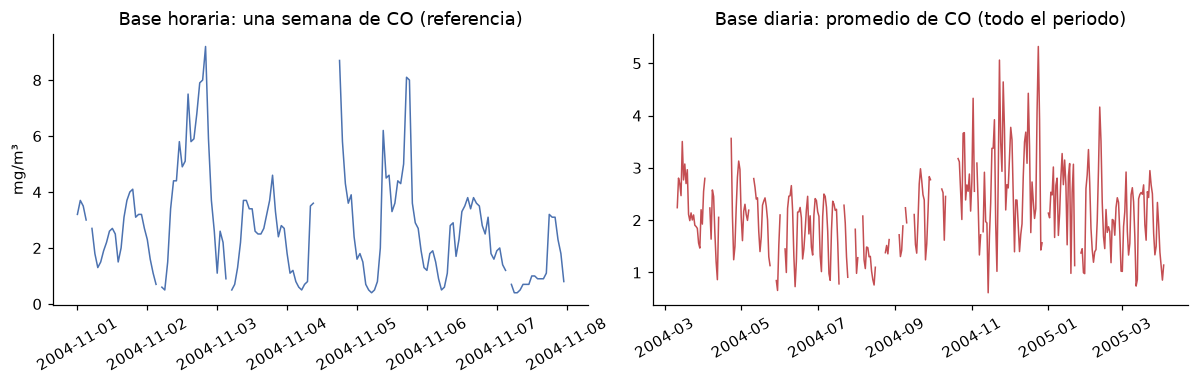

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

semana = horario[(horario["fecha_hora"] >= "2004-11-01") & (horario["fecha_hora"] < "2004-11-08")]
axes[0].plot(semana["fecha_hora"], semana["co_ref"], color="#4c72b0", lw=1)
axes[0].set_title("Base horaria: una semana de CO (referencia)")
axes[0].set_ylabel("mg/m³")
axes[0].tick_params(axis="x", rotation=30)

axes[1].plot(pd.to_datetime(diario["fecha"]), diario["co_ref"], color="#c44e52", lw=1)
axes[1].set_title("Base diaria: promedio de CO (todo el periodo)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 8. Entregables: diccionario, datasets, README y estructura de archivos

Ahora generamos los **entregables de documentación**. El diccionario de datos se arma con código a partir de metadatos que declaramos una sola vez, y los rangos y los faltantes se calculan **desde los datos**, de modo que el diccionario no puede quedar desactualizado respecto a la base.

In [16]:
FUENTE_UCI = "UCI Air Quality (De Vito et al.)"
ref_sensor = "Respuesta nominal del sensor de óxido metálico (sin unidad)"

meta = {
    # variable: (tipo, unidad, descripcion, fuente, transformacion)
    "fecha_hora": ("Fecha-hora", "aaaa-mm-dd hh:mm", "Hora de la medición (promedio horario)", FUENTE_UCI,
                   "Columnas Date y Time unidas; convertidas a fecha-hora (formato dd/mm/aaaa y hh.mm.ss)"),
    "co_ref": ("Número", "mg/m³", "Concentración de CO medida por el analizador de referencia", FUENTE_UCI,
               "-200 convertido a faltante; NO imputado (variable a explicar)"),
    "sensor_co": ("Número", "adimensional", ref_sensor + " orientado a CO (PT08.S1)", FUENTE_UCI,
                  "-200 a faltante; interpolación temporal de huecos de hasta 3 h"),
    "benceno_ref": ("Número", "µg/m³", "Concentración de benceno medida por el analizador de referencia", FUENTE_UCI,
                    "-200 convertido a faltante; sin imputación"),
    "sensor_nmhc": ("Número", "adimensional", ref_sensor + " orientado a hidrocarburos no metánicos (PT08.S2)", FUENTE_UCI,
                    "-200 a faltante; interpolación temporal de huecos de hasta 3 h"),
    "nox_ref": ("Número", "ppb", "Concentración de NOx medida por el analizador de referencia", FUENTE_UCI,
                "-200 convertido a faltante; sin imputación"),
    "sensor_nox": ("Número", "adimensional", ref_sensor + " orientado a NOx (PT08.S3)", FUENTE_UCI,
                   "-200 a faltante; interpolación temporal de huecos de hasta 3 h"),
    "no2_ref": ("Número", "µg/m³", "Concentración de NO2 medida por el analizador de referencia", FUENTE_UCI,
                "-200 convertido a faltante; sin imputación"),
    "sensor_no2": ("Número", "adimensional", ref_sensor + " orientado a NO2 (PT08.S4)", FUENTE_UCI,
                   "-200 a faltante; interpolación temporal de huecos de hasta 3 h"),
    "sensor_o3": ("Número", "adimensional", ref_sensor + " orientado a O3 (PT08.S5)", FUENTE_UCI,
                  "-200 a faltante; interpolación temporal de huecos de hasta 3 h"),
    "temperatura": ("Número", "°C", "Temperatura", FUENTE_UCI,
                    "-200 a faltante; interpolación temporal de huecos de hasta 3 h"),
    "humedad_rel": ("Número", "%", "Humedad relativa", FUENTE_UCI,
                    "-200 a faltante; interpolación temporal de huecos de hasta 3 h"),
    "humedad_abs": ("Número", "no documentada por la fuente", "Humedad absoluta", FUENTE_UCI,
                    "-200 a faltante; interpolación temporal de huecos de hasta 3 h"),
    "hay_imputacion": ("Sí/No", "-", "La fila tiene al menos un valor imputado", "Derivada",
                       "Calculada al interpolar"),
    "hora_del_dia": ("Entero", "hora", "Hora del día de la medición", "Derivada", "Extraída de fecha_hora"),
    "dia_semana": ("Entero", "-", "Día de la semana (0 = lunes ... 6 = domingo)", "Derivada", "Extraída de fecha_hora"),
    "es_fin_de_semana": ("Sí/No", "-", "Sábado o domingo", "Derivada", "Calculada desde dia_semana"),
    # variables propias de la base diaria
    "fecha": ("Fecha", "aaaa-mm-dd", "Día calendario", "Derivada", "Agregación diaria de fecha_hora"),
    "horas_validas_co_ref": ("Entero", "horas", "Horas con dato de co_ref ese día (0 a 24)", "Derivada",
                             "Conteo de horas no faltantes"),
}

def rango(serie):
    s = serie.dropna()
    if s.empty:
        return "sin datos"
    if pd.api.types.is_bool_dtype(serie):
        return "verdadero o falso"
    if pd.api.types.is_datetime64_any_dtype(serie):
        return f"{s.min():%Y-%m-%d} a {s.max():%Y-%m-%d}"
    if pd.api.types.is_numeric_dtype(serie):
        return f"{s.min():.2f} a {s.max():.2f}"
    return f"{s.min()} a {s.max()}"

def armar_diccionario(base, nombre_archivo, es_diaria=False):
    filas = []
    for col in base.columns:
        tipo, unidad, desc, fuente, transf = meta[col]
        if es_diaria and col in cols_agregar:
            transf = f"Promedio diario de la base horaria, solo con ≥ {MIN_HORAS} h válidas; " + transf
            fuente = FUENTE_UCI + " (agregada)"
        faltante = base[col].isna().mean()
        filas.append({
            "archivo": nombre_archivo,
            "variable": col,
            "tipo": tipo,
            "unidad": unidad,
            "valores_observados": rango(base[col]),
            "puede_estar_vacio": "Sí" if faltante > 0 else "No",
            "porcentaje_faltante": round(100 * faltante, 1),
            "descripcion": desc,
            "fuente": fuente,
            "transformacion_aplicada": transf,
        })
    return pd.DataFrame(filas)

# Para el diccionario de la base diaria reutilizamos la metadata de la horaria
meta_diaria_cols = ["fecha"] + cols_agregar + ["horas_validas_co_ref", "dia_semana"]
diccionario = pd.concat([
    armar_diccionario(horario, "calidad_aire_horario.csv"),
    armar_diccionario(diario[meta_diaria_cols], "calidad_aire_diario.csv", es_diaria=True),
], ignore_index=True)

diccionario.head(8)

,archivo,variable,tipo,unidad,valores_observados,puede_estar_vacio,porcentaje_faltante,descripcion,fuente,transformacion_aplicada
0,calidad_aire_horario.csv,fecha_hora,Fecha-hora,aaaa-mm-dd hh:mm,2004-03-10 a 2005-04-04,No,0.00,Hora de la medición (promedio horario),UCI Air Quality (De Vito et al.),Columnas Date y Time unidas; convertidas a fec...
1,calidad_aire_horario.csv,co_ref,Número,mg/m³,0.10 a 11.90,Sí,18.00,Concentración de CO medida por el analizador d...,UCI Air Quality (De Vito et al.),-200 convertido a faltante; NO imputado (varia...
2,calidad_aire_horario.csv,sensor_co,Número,adimensional,647.00 a 2040.00,Sí,3.50,Respuesta nominal del sensor de óxido metálico...,UCI Air Quality (De Vito et al.),-200 a faltante; interpolación temporal de hue...
3,calidad_aire_horario.csv,benceno_ref,Número,µg/m³,0.10 a 63.70,Sí,3.90,Concentración de benceno medida por el analiza...,UCI Air Quality (De Vito et al.),-200 convertido a faltante; sin imputación
4,calidad_aire_horario.csv,sensor_nmhc,Número,adimensional,383.00 a 2214.00,Sí,3.50,Respuesta nominal del sensor de óxido metálico...,UCI Air Quality (De Vito et al.),-200 a faltante; interpolación temporal de hue...
5,calidad_aire_horario.csv,nox_ref,Número,ppb,2.00 a 1479.00,Sí,17.50,Concentración de NOx medida por el analizador ...,UCI Air Quality (De Vito et al.),-200 convertido a faltante; sin imputación
6,calidad_aire_horario.csv,sensor_nox,Número,adimensional,322.00 a 2683.00,Sí,3.50,Respuesta nominal del sensor de óxido metálico...,UCI Air Quality (De Vito et al.),-200 a faltante; interpolación temporal de hue...
7,calidad_aire_horario.csv,no2_ref,Número,µg/m³,2.00 a 340.00,Sí,17.50,Concentración de NO2 medida por el analizador ...,UCI Air Quality (De Vito et al.),-200 convertido a faltante; sin imputación


In [17]:
# Guardamos los entregables con la estructura de carpetas recomendada
horario.to_csv(RAIZ / "datos/procesados/calidad_aire_horario.csv", index=False)
diario[meta_diaria_cols].to_csv(RAIZ / "datos/procesados/calidad_aire_diario.csv", index=False)
diccionario.to_csv(RAIZ / "datos/diccionario_datos.csv", index=False, encoding="utf-8")

print("Base horaria:", horario.shape, "| Base diaria:", diario[meta_diaria_cols].shape)
print("Diccionario:", diccionario.shape)

Base horaria: (9357, 17) | Base diaria: (391, 15)
Diccionario: (32, 10)


In [18]:
readme = f'''# Calidad del aire: estimación de CO con sensores económicos (ejemplo)

Ejemplo didáctico de la Unidad 4 (Seminario de Proyecto I, MCDI). Documenta el camino de los datos crudos a un dataset listo para análisis.

## Pregunta de investigación
¿Qué tan bien se puede estimar la concentración de CO medida por un analizador de referencia a partir de sensores económicos de óxido metálico y de variables meteorológicas?

## Objetivos e hipótesis
- **Objetivo general:** evaluar en qué medida la concentración de CO de referencia puede estimarse con sensores económicos y variables meteorológicas.
- **Hipótesis general:** la señal de los sensores, junto con la temperatura y la humedad, permite estimar el CO de referencia en periodos posteriores al de ajuste del modelo.
- **OE1 / H1:** cuantificar la relación sensor-referencia / a mayor señal del sensor, mayor CO de referencia.
- **OE2 / H2:** determinar si temperatura y humedad mejoran la estimación / con ellas el error es menor que con el sensor solo.
- **OE3 / H3:** describir la variación horaria y semanal / el CO es mayor en horas de tráfico y días laborales.
- **OE4 / H4:** describir la serie diaria y la estación del año / los promedios diarios son más altos en meses fríos.

## Origen de los datos
- **Fuente:** UCI Machine Learning Repository, dataset *Air Quality*. {URL}
- **Autoría:** Vito, S. (2008). Datos generados por S. De Vito y colaboradores (ENEA, Italia).
- **Fecha de descarga:** {ruta_origen.read_text(encoding="utf-8").splitlines()[1].split(": ")[1]}
- **Licencia y uso:** CC BY 4.0 según UCI; la página indica además uso solo para investigación, no comercial. No se redistribuye el archivo original.
- **Cobertura real:** {horario["fecha_hora"].min():%Y-%m-%d} a {horario["fecha_hora"].max():%Y-%m-%d}, promedios horarios, una sola estación (la documentación anuncia hasta febrero de 2005).

## Estructura
```
datos/originales/       archivo tal como se descargó (no se modifica)
datos/procesados/       calidad_aire_horario.csv, calidad_aire_diario.csv
datos/diccionario_datos.csv
documentos/             material de apoyo del proyecto
README.md
```

## Transformaciones (resumen; el detalle está en el diccionario)
1. Se eliminaron {int(filas_vacias.sum())} filas y {len(columnas_vacias)} columnas completamente vacías.
2. El valor -200 (centinela de faltante) se convirtió en dato faltante real.
3. Se unieron fecha y hora en una sola marca de tiempo.
4. Se descartó `nmhc_ref` (~90 % faltante).
5. Se interpolaron solo huecos de hasta 3 horas en sensores y meteorología; no se imputó `co_ref` ni los apagones largos.
6. Se crearon variables derivadas (`hora_del_dia`, `dia_semana`, `es_fin_de_semana`, `hay_imputacion`).
7. Base diaria: promedio con al menos {MIN_HORAS} horas válidas por día.

## Limitaciones
- Una sola estación y una sola ciudad: no se puede generalizar a otras zonas.
- Los sensores presentan sensibilidad cruzada y deriva temporal.
- La zona horaria y la unidad de `humedad_abs` no están documentadas.
- `co_ref` falta en ~18 % de las horas; las filas sin él se excluyen de los modelos.

## Referencias
Vito, S. (2008). *Air Quality* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C59K5F

De Vito, S., Massera, E., Piga, M., Martinotto, L., & Di Francia, G. (2008). On field calibration of an electronic nose for benzene estimation in an urban pollution monitoring scenario. *Sensors and Actuators B: Chemical, 129*(2), 750-757. https://doi.org/10.1016/j.snb.2007.09.060
'''
(RAIZ / "README.md").write_text(readme, encoding="utf-8")
print(readme[:900], "...")

# Calidad del aire: estimación de CO con sensores económicos (ejemplo)

Ejemplo didáctico de la Unidad 4 (Seminario de Proyecto I, MCDI). Documenta el camino de los datos crudos a un dataset listo para análisis.

## Pregunta de investigación
¿Qué tan bien se puede estimar la concentración de CO medida por un analizador de referencia a partir de sensores económicos de óxido metálico y de variables meteorológicas?

## Objetivos e hipótesis
- **Objetivo general:** evaluar en qué medida la concentración de CO de referencia puede estimarse con sensores económicos y variables meteorológicas.
- **Hipótesis general:** la señal de los sensores, junto con la temperatura y la humedad, permite estimar el CO de referencia en periodos posteriores al de ajuste del modelo.
- **OE1 / H1:** cuantificar la relación sensor-referencia / a mayor señal del sensor, mayor CO de referencia.
- **OE2 / H2:** determ ...


## 9. Una primera mirada de uso y lista de verificación

El dataset ya está listo para análisis. Hacemos una **primera mirada** para comprobar que responde a la pregunta (esto no es todavía el análisis del proyecto): ajustamos un modelo lineal simple que estima `co_ref` con `sensor_co`, `temperatura` y `humedad_rel`.

Dos precauciones que vienen de la presentación:

- **No se imputó la variable a explicar**, así que usamos solo las horas con `co_ref` observado.
- **División temporal:** entrenamos con el primer 80% del periodo y evaluamos con el último 20%. Si mezcláramos las horas al azar, el modelo "vería el futuro" (fuga de información, *data leakage*).

**Qué hipótesis toca esta primera mirada.** Solo la hipótesis general y, de forma descriptiva, la H1. Lo importante es comprobar que la base **permite** contrastar también la H2 (están `temperatura` y `humedad_rel`), la H3 (`hora_del_dia`, `dia_semana`) y la H4 (la base diaria conserva la fecha).

In [19]:
modelo_df = horario.dropna(subset=["co_ref", "sensor_co", "temperatura", "humedad_rel"]).sort_values("fecha_hora")
corte = int(0.8 * len(modelo_df))
entrena, prueba = modelo_df.iloc[:corte], modelo_df.iloc[corte:]

X_cols = ["sensor_co", "temperatura", "humedad_rel"]
modelo = LinearRegression().fit(entrena[X_cols], entrena["co_ref"])
pred = modelo.predict(prueba[X_cols])

print(f"Horas usadas: {len(modelo_df)}  (entrenamiento: {len(entrena)}, prueba: {len(prueba)})")
print(f"Correlación sensor_co vs co_ref (todo el periodo): {modelo_df['sensor_co'].corr(modelo_df['co_ref']):.2f}")
print(f"R² en el periodo de prueba: {r2_score(prueba['co_ref'], pred):.2f}")
print(f"Error medio absoluto en prueba: {mean_absolute_error(prueba['co_ref'], pred):.2f} mg/m³")

Horas usadas: 7376  (entrenamiento: 5900, prueba: 1476)
Correlación sensor_co vs co_ref (todo el periodo): 0.88
R² en el periodo de prueba: 0.70
Error medio absoluto en prueba: 0.55 mg/m³


> Aunque el resultado sea razonable, **no lo interpretes como una conclusión científica**: el sitio es único, los sensores tienen deriva (la relación puede cambiar con el tiempo) y solo usamos un modelo lineal básico. La finalidad aquí es comprobar que la base permite abordar la pregunta.

### Lista de buenas prácticas (cómo la cumple este ejemplo)

| Requisito | Dónde se cumple en este ejemplo |
|---|---|
| Archivo de base de datos creado | `datos/procesados/calidad_aire_horario.csv` y `calidad_aire_diario.csv` |
| Herramienta utilizada | Python (pandas) en este notebook |
| Alineación metodológica explícita | Sección 1: pregunta → objetivo → hipótesis → variable/métrica |
| Evaluación del origen de datos | Sección 2 (6 dimensiones) y hallazgos de la sección 3 |
| Variables incluidas listadas | `diccionario_datos.csv` (tipo, unidad, rango y % faltante por variable) |
| Transformaciones documentadas | Columna `transformacion_aplicada` del diccionario y README |
| Diccionario de datos completo | `datos/diccionario_datos.csv` |
| Video corto y PDF (Evidencia 4A) | **Los produces tú** con tu propia base (aquí no aplican) |

## Referencias

De Vito, S., Massera, E., Piga, M., Martinotto, L., & Di Francia, G. (2008). On field calibration of an electronic nose for benzene estimation in an urban pollution monitoring scenario. *Sensors and Actuators B: Chemical, 129*(2), 750-757. https://doi.org/10.1016/j.snb.2007.09.060

Vito, S. (2008). *Air Quality* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C59K5F